## View and explore the dataset

In [1]:
import pickle
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from utils import plot_machine_signals, plot_machine_delta_signals
from utils import plot_machine_multi_figure, plot_ren_multi_figure
from utils import plot_bus_voltages_rms, plot_voltages_heatmap
from utils import plot_bus_voltage, plot_frequency
from utils import tsi_from_angle, features_engineering, corrupt_measurements
from utils import (
    train_extra_trees_classifier,
    train_hist_gradient_boosting_classifier,
    train_random_forest_classifier
)

### Reading external pickle file with simulation signals

In [3]:
file_name = 'V1-T100ms.pkl'  # EDIT HERE
variant = file_name.split('-')[0]
file_path = pathlib.Path.home()/'Downloads/Data/'/file_name
with open(file=file_path, mode='rb') as fp:
    data_all = pickle.load(fp)

In [4]:
# Key for the SC type and location:
key = 'SC2-BUS19'  # EDIT HERE

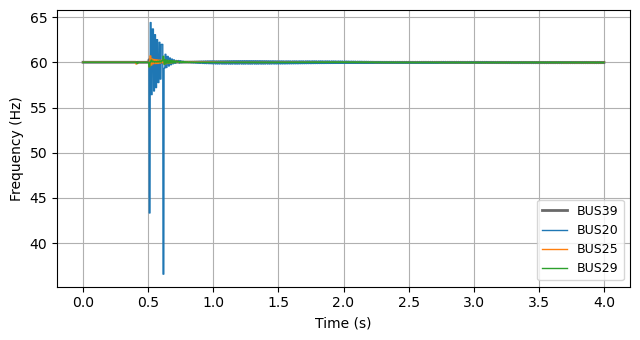

In [5]:
plot_frequency(data_all[key], [39, 20, 25, 29], raw=True)

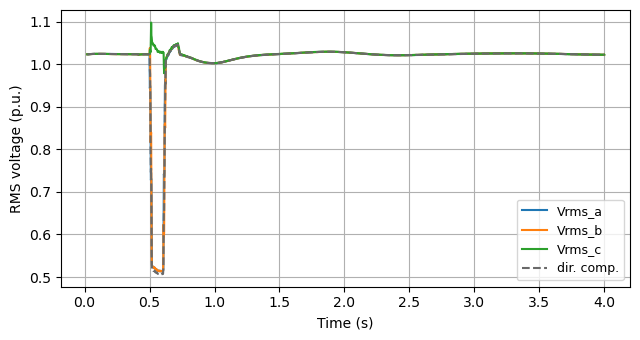

In [6]:
plot_bus_voltages_rms(data_all[key], 'BUS19')

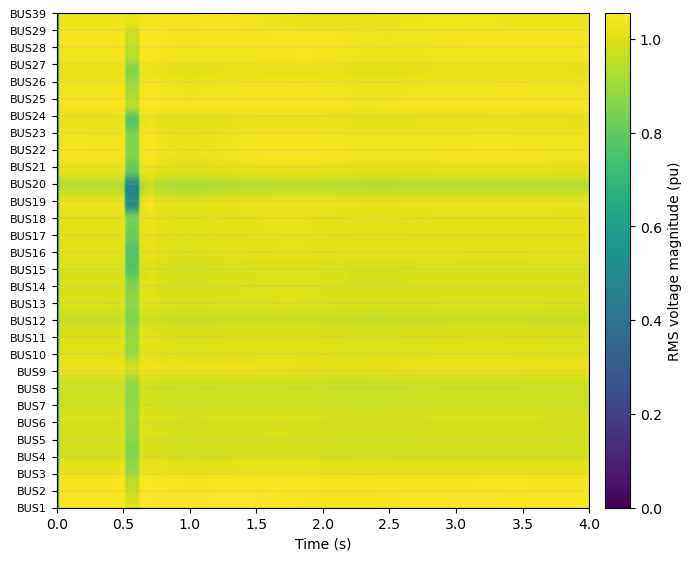

In [7]:
plot_voltages_heatmap(data_all, key)

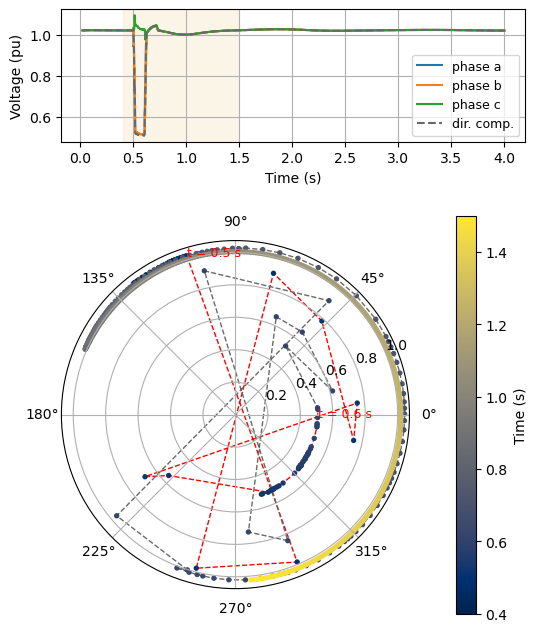

In [8]:
# Bus voltages:
plot_bus_voltage(data_all, key, 'BUS19', 0.1, 1.5)

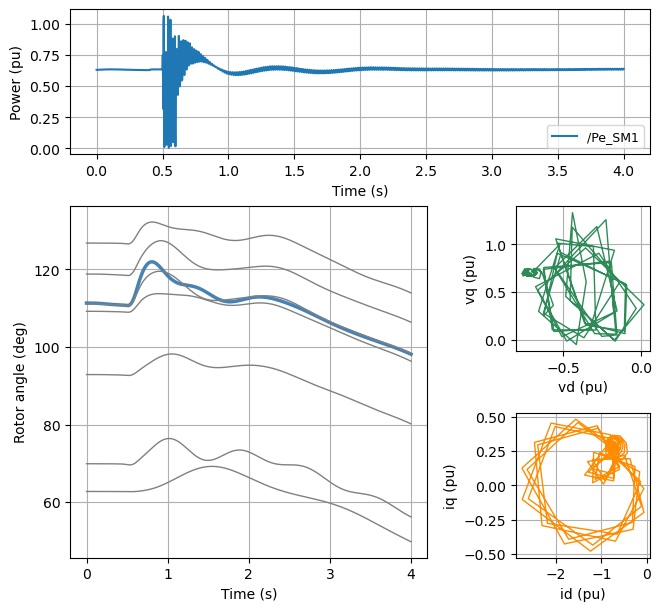

In [9]:
# Machine signals:
plant = 'PowerPlant_04'  # EDIT HERE
plot_machine_multi_figure(data_all, key, plant)

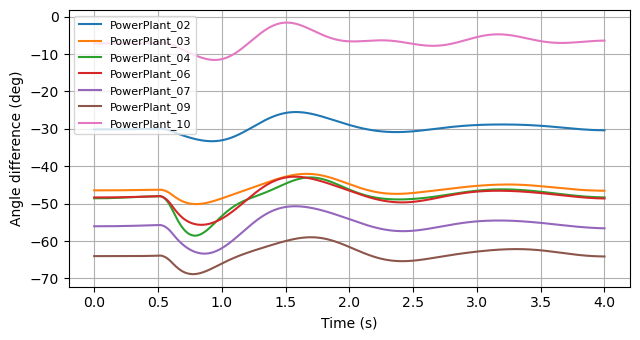

In [10]:
plot_machine_delta_signals(data_all[key])

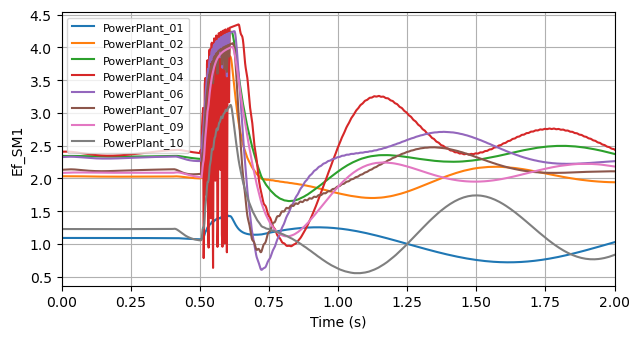

In [11]:
plot_machine_signals(data_all[key], 'Ef_SM1', xlim=2)

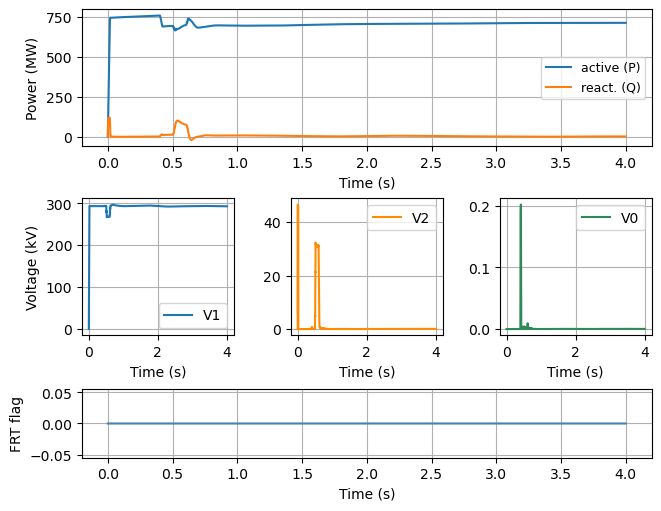

In [12]:
# Wind farm signals:
if variant in ['V1', 'V2', 'V3', 'V4', 'V5']:
    plot_ren_multi_figure(data_all, key, 'WF')

In [13]:
# Wind farm WF2 signals:
if variant in ['V2', 'V3', 'V4', 'V5']:
    plot_ren_multi_figure(data_all, key, 'WF2')

In [14]:
# Wind farm WF3 signals:
if variant == 'V5':
    plot_ren_multi_figure(data_all, key, 'WF3')

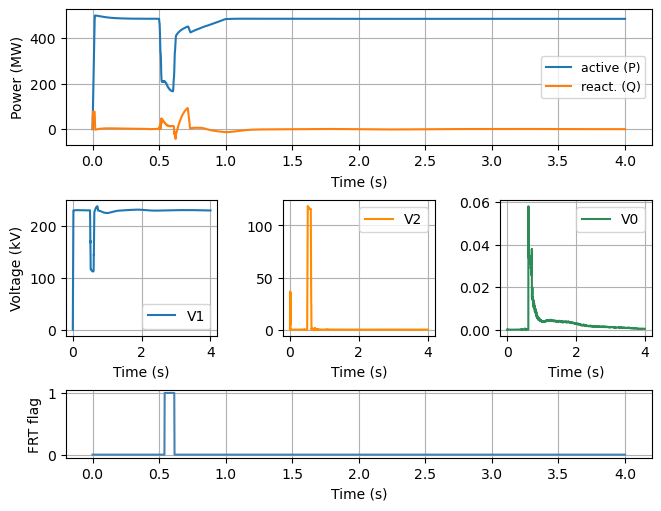

In [15]:
# PV plant signals:
if variant in ['V1', 'V2', 'V3', 'V4', 'V5']:
    plot_ren_multi_figure(data_all, key, 'PV')

In [16]:
# PV2 plant signals:
if variant in ['V2', 'V3', 'V4', 'V5']:
    plot_ren_multi_figure(data_all, key, 'PV2')

In [17]:
# PV3 plant signals:
if variant in ['V4', 'V5']:
    plot_ren_multi_figure(data_all, key, 'PV3')

In [18]:
# PV4 plant signals:
if variant == 'V5':
    plot_ren_multi_figure(data_all, key, 'PV4')

In [19]:
# Transient stability index.
for key in data_all.keys():
    if key == 'README':
        continue
    tsi = tsi_from_angle(data_all[key])
    # TSI = 1 is unstable.
    print(f'{key}: {tsi}')
    if variant in ['V1', 'V2', 'V3', 'V4', 'V5']:
        print(f' WF-FRT: {int(data_all[key]['WF/FRT_flag'].sum())}')
        print(f' PV-FRT: {int(data_all[key]['PV/FRT_flag'].sum())}')
    if variant in ['V2', 'V3', 'V4', 'V5']:
        print(f' WF2-FRT: {int(data_all[key]['WF2/FRT_flag'].sum())}')
        print(f' PV2-FRT: {int(data_all[key]['PV2/FRT_flag'].sum())}')
    if variant in ['V4', 'V5']:
        print(f' PV3-FRT: {int(data_all[key]['PV3/FRT_flag'].sum())}')
    if variant == 'V5':
        print(f' WF3-FRT: {int(data_all[key]['WF3/FRT_flag'].sum())}')
        print(f' PV4-FRT: {int(data_all[key]['PV4/FRT_flag'].sum())}')

SC3-BUS1: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS2: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS3: 0
 WF-FRT: 125
 PV-FRT: 22
SC3-BUS4: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS5: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS6: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS7: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS8: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS9: 0
 WF-FRT: 0
 PV-FRT: 0
SC3-BUS10: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS11: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS12: 0
 WF-FRT: 0
 PV-FRT: 0
SC3-BUS13: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS14: 0
 WF-FRT: 125
 PV-FRT: 8
SC3-BUS15: 0
 WF-FRT: 125
 PV-FRT: 43
SC3-BUS16: 0
 WF-FRT: 125
 PV-FRT: 53
SC3-BUS17: 0
 WF-FRT: 125
 PV-FRT: 45
SC3-BUS18: 0
 WF-FRT: 125
 PV-FRT: 34
SC3-BUS19: 0
 WF-FRT: 125
 PV-FRT: 58
SC3-BUS20: 0
 WF-FRT: 0
 PV-FRT: 58
SC3-BUS21: 0
 WF-FRT: 125
 PV-FRT: 41
SC3-BUS22: 0
 WF-FRT: 125
 PV-FRT: 33
SC3-BUS23: 0
 WF-FRT: 125
 PV-FRT: 29
SC3-BUS24: 0
 WF-FRT: 125
 PV-FRT: 46
SC3-BUS25: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS26: 0
 WF-FRT: 125
 PV-FRT: 0
SC3-BUS27: 0
 WF-FRT: 125
 PV-FRT: 5
SC3-B

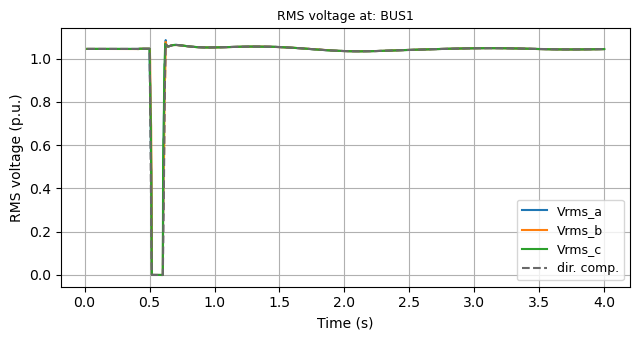

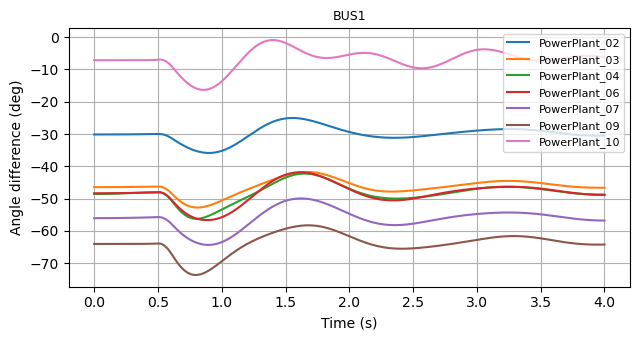

In [20]:
# Plots from multiple scenarios.`
sc_type = 'SC3'  # EDIT HERE
bus_for_plot = [f'BUS{i}' for i in range(1, 2)]  # EDIT HERE
for key in data_all.keys():
    if key == 'README':
        continue
    sc, bus = key.split('-')
    if sc == sc_type and bus in bus_for_plot:
        plot_bus_voltages_rms(data_all[key], bus, title=True)
        plot_machine_delta_signals(data_all[key], title=bus)

## Machine learning for grid stability assessment

In [21]:
from utils import calibrate_model, tune_model_threshold, evaluate_classifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    RocCurveDisplay,
)

In [22]:
set1 = 'V0-T100ms.pkl'
path1 = pathlib.Path.home()/'Downloads/Data/'/set1
data1 = features_engineering(path1)
set2 = 'V0-T300ms.pkl'
path2 = pathlib.Path.home()/'Downloads/Data/'/set2
data2 = features_engineering(path2)
# Concatenate features.
train_data = pd.concat([data1, data2], ignore_index=True)
pct = (train_data['TSI'].sum() / len(train_data['TSI'])) * 100
print(f' Pct. of unstable cases: {pct:.2f} %')

 Pct. of unstable cases: 9.38 %


In [23]:
# Random subset from the training set.
train_sample, calibration_sample = train_test_split(
    train_data,
    train_size=0.8,
    shuffle=True,
    stratify=train_data['TSI'].values
)
train_sample

,F1,F2,F3,F4,F5,F6,F7,F8,F9,F10,...,F50,F51,F52,F53,F54,F55,F56,F57,F58,TSI
30,0.375,1.058,0.568,1.048,0.691,1.023,0.776,0.992,0.819,0.998,...,1.043,0.768,1.041,0.772,1.026,0.842,1.043,0.868,1.047,False
235,0.920,1.099,0.981,1.083,0.943,1.053,0.874,1.016,0.845,1.021,...,1.080,0.991,1.073,0.969,1.056,1.007,1.074,1.014,1.076,False
39,0.905,1.054,0.833,1.048,0.686,1.015,0.406,0.970,0.210,0.969,...,1.046,0.843,1.042,0.792,1.023,0.901,1.048,0.921,1.053,False
280,1.007,1.054,0.968,1.064,0.905,1.030,0.880,0.996,0.902,1.002,...,1.065,0.933,1.058,0.887,1.034,0.963,1.071,0.975,1.078,False
230,0.977,1.061,0.940,1.068,0.853,1.031,0.694,0.975,0.591,0.967,...,1.069,0.942,1.068,0.908,1.047,0.972,1.080,0.983,1.086,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.998,1.054,0.957,1.055,0.883,1.027,0.798,0.991,0.825,0.996,...,1.054,0.938,1.049,0.898,1.032,0.968,1.053,0.980,1.057,False
107,0.976,1.054,0.929,1.054,0.834,1.024,0.674,0.985,0.629,0.988,...,1.052,0.925,1.048,0.887,1.030,0.959,1.053,0.972,1.056,False
204,0.904,0.972,0.808,0.960,0.647,0.890,0.367,0.773,0.318,0.736,...,0.968,0.806,0.969,0.746,0.936,0.873,1.005,0.896,1.019,True
270,0.991,1.059,0.952,1.068,0.872,1.032,0.740,0.979,0.723,0.974,...,1.069,0.947,1.067,0.913,1.047,0.975,1.078,0.986,1.084,False


In [24]:
# Test model on Variant V1.
set1 = 'V1-T100ms.pkl'
path1 = pathlib.Path.home()/'Downloads/Data/'/set1
data1 = features_engineering(path1)
set2 = 'V1-T300ms.pkl'
path2 = pathlib.Path.home()/'Downloads/Data/'/set2
data2 = features_engineering(path2)
# Concatenate features.
test_data = pd.concat([data1, data2], ignore_index=True)
pct = (test_data['TSI'].sum() / len(test_data['TSI'])) * 100
print(f' Pct. of unstable cases: {pct:.2f} %')

 Pct. of unstable cases: 6.60 %


In [25]:
# Random sample from the test set.
test_sample, y_true = train_test_split(
    test_data,
    train_size=0.5,
    shuffle=True,
    stratify=test_data['TSI'].values
)
test_sample

,F1,F2,F3,F4,F5,F6,F7,F8,F9,F10,...,F50,F51,F52,F53,F54,F55,F56,F57,F58,TSI
68,0.964,1.050,0.919,1.046,0.816,1.015,0.635,0.981,0.525,0.986,...,1.044,0.919,1.039,0.879,1.020,0.957,1.047,0.971,1.051,False
145,1.017,1.049,0.990,1.049,0.935,1.020,0.908,0.987,0.926,0.993,...,1.048,0.962,1.041,0.922,1.023,0.986,1.045,0.995,1.049,False
9,0.898,1.043,0.808,1.033,0.646,0.998,0.363,0.958,0.296,0.962,...,1.030,0.810,1.025,0.746,1.004,0.880,1.036,0.904,1.042,False
4,0.876,1.046,0.786,1.035,0.609,1.001,0.269,0.962,0.000,0.966,...,1.031,0.802,1.027,0.741,1.006,0.876,1.037,0.900,1.042,False
270,0.989,1.054,0.951,1.061,0.868,1.026,0.739,0.980,0.725,0.981,...,1.060,0.945,1.058,0.908,1.037,0.975,1.070,0.986,1.077,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,0.860,1.045,0.651,1.040,0.737,1.014,0.805,0.988,0.849,0.997,...,1.036,0.751,1.016,0.768,1.006,0.820,1.005,0.844,1.007,False
85,0.998,1.046,0.954,1.043,0.882,1.012,0.860,0.981,0.886,0.988,...,1.042,0.913,1.035,0.859,1.014,0.950,1.043,0.964,1.048,False
37,0.874,1.043,0.754,1.032,0.557,0.998,0.192,0.961,0.356,0.969,...,1.028,0.764,1.023,0.693,1.002,0.847,1.033,0.875,1.039,False
16,0.821,1.035,0.615,1.017,0.399,0.982,0.511,0.955,0.607,0.967,...,1.011,0.419,0.993,0.222,0.973,0.582,0.997,0.635,1.002,False


#### Dummy Classifier

In [26]:
# Benchmark (dummy model) that predicts all cases as stable.
y_true = test_sample['TSI'].values
# Dummy model predicts all zeros (stable cases).
y_pred = np.zeros_like(y_true)

# Evaluation of predictions.
print('DUMMY CLASSIFIER:')
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
print(classification_report(y_true, y_pred, digits=3, zero_division=0.0))
bac = balanced_accuracy_score(y_true, y_pred)
print(f'Balanced accuracy score: {bac:.4f}')

DUMMY CLASSIFIER:
[[135   0]
 [  9   0]]
              precision    recall  f1-score   support

       False      0.938     1.000     0.968       135
        True      0.000     0.000     0.000         9

    accuracy                          0.938       144
   macro avg      0.469     0.500     0.484       144
weighted avg      0.879     0.938     0.907       144

Balanced accuracy score: 0.5000


In [27]:
trained_models = {}

### Extremely Randomized Trees Classifier

In [28]:
# Train model on random subset from the Variant V0 data.
model = train_extra_trees_classifier(train_sample)
# Calibrate model using cross-validation.
#model = calibrate_model(base_model, calibration_sample)
# Tune decision threshold.
#thr = tune_model_threshold(model, calibration_sample)
trained_models['ExtraTrees'] = model

Fitting 3 folds for each of 100 candidates, totalling 300 fits


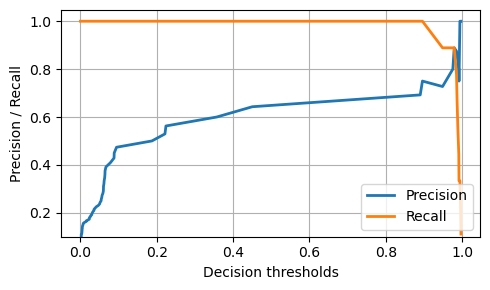

Confusion matrix:
[[131   4]
 [  0   9]]

Classification report:
              precision    recall  f1-score   support

       False      1.000     0.970     0.985       135
        True      0.692     1.000     0.818         9

    accuracy                          0.972       144
   macro avg      0.846     0.985     0.902       144
weighted avg      0.981     0.972     0.975       144

Balanced accuracy: 0.9852
ROC AUC: 0.9934
PR AUC (average precision): 0.8894
PR AUC: 0.8804
ROC AUC (3-fold CV) Score: 0.9901 +/- 0.0092


In [29]:
# Evaluate model predictions.
comparison = evaluate_classifier(model, test_sample)

In [30]:
# Retain model instance for later use.
selected_model = model

### Histogram-based Gradient Boosting Classification Tree

In [31]:
# Train model on random subset from the Variant V0 data.
model = train_hist_gradient_boosting_classifier(train_sample)
trained_models['HGBCT'] = model

Fitting 3 folds for each of 100 candidates, totalling 300 fits


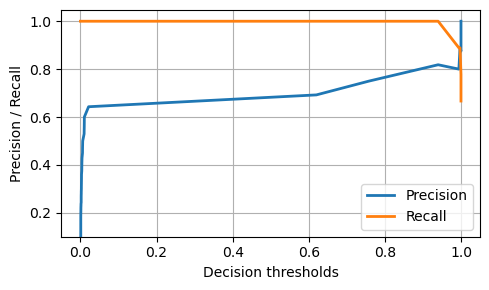

Confusion matrix:
[[131   4]
 [  0   9]]

Classification report:
              precision    recall  f1-score   support

       False      1.000     0.970     0.985       135
        True      0.692     1.000     0.818         9

    accuracy                          0.972       144
   macro avg      0.846     0.985     0.902       144
weighted avg      0.981     0.972     0.975       144

Balanced accuracy: 0.9852
ROC AUC: 0.9971
PR AUC (average precision): 0.9536
PR AUC: 0.9587
ROC AUC (3-fold CV) Score: 0.9741 +/- 0.0157


In [32]:
# Evaluate model predictions.
comparison = evaluate_classifier(model, test_sample)

### Random Forest Classifier

In [33]:
# Train model on random subset from the Variant V0 data.
model = train_random_forest_classifier(train_sample)
trained_models['RF'] = model

Fitting 3 folds for each of 100 candidates, totalling 300 fits


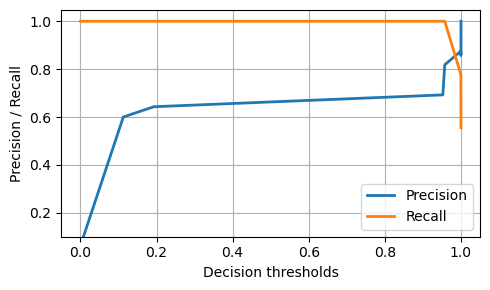

Confusion matrix:
[[131   4]
 [  0   9]]

Classification report:
              precision    recall  f1-score   support

       False      1.000     0.970     0.985       135
        True      0.692     1.000     0.818         9

    accuracy                          0.972       144
   macro avg      0.846     0.985     0.902       144
weighted avg      0.981     0.972     0.975       144

Balanced accuracy: 0.9852
ROC AUC: 0.9963
PR AUC (average precision): 0.9298
PR AUC: 0.9431
ROC AUC (3-fold CV) Score: 0.9383 +/- 0.0742


In [34]:
# Evaluate model predictions.
comparison = evaluate_classifier(model, test_sample)

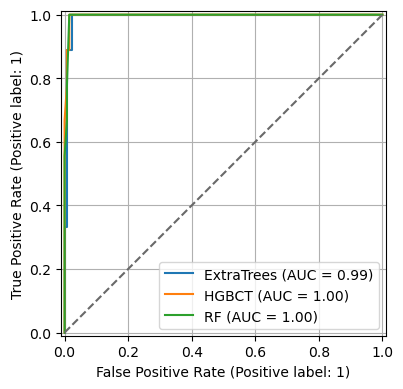

In [35]:
# Model comparison (ROC curves).
fig = plt.figure(figsize=(4.5, 4))
ax = fig.add_subplot()
for key, value in trained_models.items():
    RocCurveDisplay.from_estimator(
        value,  # estimator
        test_sample.iloc[:, :-1],
        y_true.astype(int),
        pos_label=1,
        name=key,
        ax=ax,
    )
ax.grid(which='major', axis='both')
ax.plot([0, 1], [0, 1], ls='--', c='dimgrey')
fig.tight_layout()
#plt.savefig('roc-auc.pdf')
plt.show()

### Simulating Malfunctioning PMUs

In [36]:
# Corrupting voltage measurements.
for bus in [5, 10, 15, 20, 25]:
    test_sample = corrupt_measurements(test_sample, bus, 20)
test_sample

,F1,F2,F3,F4,F5,F6,F7,F8,F9,F10,...,F50,F51,F52,F53,F54,F55,F56,F57,F58,TSI
68,0.964,1.050,0.919,1.046,0.816,1.015,0.635,0.981,0.525,0.986,...,1.044,0.919,1.039,0.879,1.020,0.957,1.047,0.971,1.051,False
145,1.017,1.049,0.990,1.049,0.935,1.020,0.908,0.987,0.926,0.993,...,NaN,0.962,1.041,0.922,1.023,0.986,1.045,0.995,1.049,False
9,0.898,1.043,0.808,1.033,0.646,0.998,0.363,0.958,0.296,0.962,...,NaN,0.810,1.025,0.746,1.004,0.880,1.036,0.904,1.042,False
4,0.876,1.046,0.786,1.035,0.609,1.001,0.269,0.962,0.000,0.966,...,1.031,0.802,1.027,0.741,1.006,0.876,1.037,0.900,1.042,False
270,0.989,1.054,0.951,1.061,0.868,1.026,0.739,0.980,NaN,NaN,...,1.060,0.945,1.058,0.908,1.037,0.975,1.070,0.986,1.077,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,0.860,1.045,0.651,1.040,0.737,1.014,0.805,0.988,NaN,NaN,...,1.036,0.751,1.016,0.768,1.006,0.820,1.005,0.844,1.007,False
85,0.998,1.046,0.954,1.043,0.882,1.012,0.860,0.981,0.886,0.988,...,1.042,0.913,1.035,0.859,1.014,0.950,1.043,0.964,1.048,False
37,0.874,1.043,0.754,1.032,0.557,0.998,0.192,0.961,0.356,0.969,...,1.028,0.764,1.023,0.693,1.002,0.847,1.033,0.875,1.039,False
16,0.821,1.035,0.615,1.017,0.399,0.982,0.511,0.955,0.607,0.967,...,1.011,0.419,0.993,0.222,0.973,0.582,0.997,0.635,1.002,False


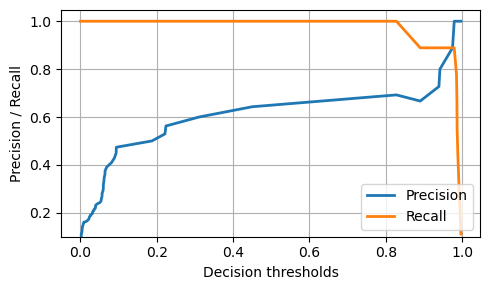

Confusion matrix:
[[131   4]
 [  0   9]]

Classification report:
              precision    recall  f1-score   support

       False      1.000     0.970     0.985       135
        True      0.692     1.000     0.818         9

    accuracy                          0.972       144
   macro avg      0.846     0.985     0.902       144
weighted avg      0.981     0.972     0.975       144

Balanced accuracy: 0.9852
ROC AUC: 0.9967
PR AUC (average precision): 0.9658
PR AUC: 0.9644
ROC AUC (3-fold CV) Score: 0.9951 +/- 0.0035


In [37]:
# Evaluate model predictions with corrupted data.
comparison = evaluate_classifier(selected_model, test_sample)

## Manifold learning for WAMS/PMU data analysis

In [38]:
from sklearn.manifold import TSNE

In [39]:
def extract_targets_shallow(data_index):
    targets = []
    for name in data_index:
        sc, _ = name.split('-')
        targets.append(str(sc[:3]))
    return targets

def extract_targets_deep(data_index, set):
    _, tsc = set.split('-')
    targets = []
    for name in data_index:
        sc, _ = name.split('-')
        targets.append(str(sc[:3]) + '('+tsc[1:6]+')')
    return targets

In [40]:
set1 = 'V0-T100ms.pkl'
path1 = pathlib.Path.home()/'Downloads/Data/'/set1
data1 = features_engineering(path1)
data1['target1'] = extract_targets_shallow(data1.index)
data1['target2'] = extract_targets_deep(data1.index, set1)
set2 = 'V0-T300ms.pkl'
path2 = pathlib.Path.home()/'Downloads/Data/'/set2
data2 = features_engineering(path2)
data2['target1'] = extract_targets_shallow(data2.index)
data2['target2'] = extract_targets_deep(data2.index, set2)
# Concatenate features.
data = pd.concat([data1, data2], ignore_index=True)

In [41]:
data

,F1,F2,F3,F4,F5,F6,F7,F8,F9,F10,...,F52,F53,F54,F55,F56,F57,F58,TSI,target1,target2
0,0.000,1.062,0.732,1.056,0.798,1.029,0.834,0.996,0.858,1.002,...,1.048,0.856,1.032,0.911,1.051,0.929,1.054,False,SC3,SC3(100ms)
1,0.543,1.037,0.000,1.013,0.311,0.994,0.550,0.970,0.650,0.979,...,1.006,0.479,0.995,0.602,1.010,0.653,1.014,False,SC3,SC3(100ms)
2,0.735,1.039,0.429,1.022,0.000,0.988,0.381,0.963,0.527,0.971,...,1.014,0.476,0.997,0.676,1.020,0.719,1.025,False,SC3,SC3(100ms)
3,0.853,1.047,0.706,1.037,0.477,1.002,0.000,0.955,0.263,0.962,...,1.030,0.666,1.011,0.818,1.038,0.847,1.043,False,SC3,SC3(100ms)
4,0.881,1.052,0.786,1.044,0.610,1.011,0.269,0.966,0.000,0.965,...,1.038,0.741,1.019,0.868,1.045,0.892,1.050,False,SC3,SC3(100ms)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,0.972,1.053,0.892,1.059,0.892,1.033,0.900,1.003,0.922,1.008,...,1.035,0.832,1.027,0.853,1.023,0.875,1.024,False,SC1,SC1(300ms)
284,0.984,1.050,0.918,1.055,0.883,1.030,0.887,1.001,0.911,1.007,...,1.020,0.711,1.016,0.803,0.996,0.830,0.995,False,SC1,SC1(300ms)
285,1.011,1.049,0.972,1.051,0.946,1.024,0.933,0.994,0.947,1.000,...,1.013,0.874,1.009,0.769,0.987,0.824,0.986,False,SC1,SC1(300ms)
286,1.015,1.048,0.980,1.049,0.954,1.023,0.938,0.992,0.952,0.998,...,1.013,0.891,1.009,0.828,0.989,0.820,0.987,False,SC1,SC1(300ms)


In [42]:
# Compute the two-dimensional tSNE embedding.
tsne = TSNE(n_components=2, perplexity=20, learning_rate='auto', init='pca', max_iter=1_000)
data_2d = tsne.fit_transform(data.iloc[:, :-3])

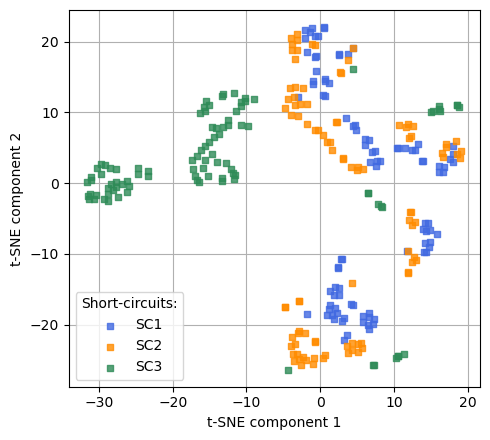

In [43]:
# Visualize the embedding (TSI index).
colors = ['royalblue', 'darkorange', 'seagreen']
fig, ax = plt.subplots(figsize=(5, 4.5))
class_names, y_encoded = np.unique(data['target1'].values, return_inverse=True)
for class_id, class_name in enumerate(class_names):
    mask = y_encoded == class_id
    ax.scatter(data_2d[mask, 0], data_2d[mask, 1], marker='s', s=20, alpha=0.8,
               color=colors[class_id], label=class_name, zorder=3)
ax.set_xlabel("t-SNE component 1")
ax.set_ylabel("t-SNE component 2")
ax.legend(title='Short-circuits:', loc='lower left')
ax.grid(which='major', axis='both', zorder=0)
fig.tight_layout()
#plt.savefig('tsne-basic.pdf')
plt.show()

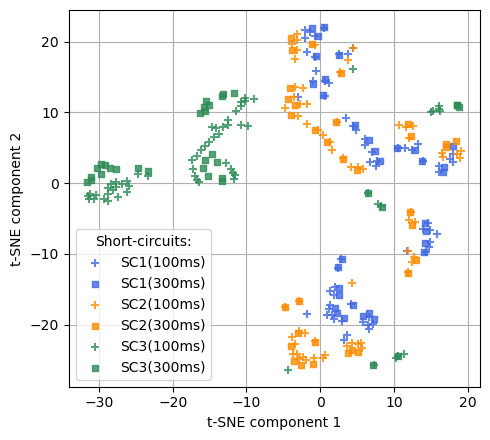

In [44]:
# Visualize the embedding (SC types).
colors = ['royalblue', 'royalblue',
          'darkorange', 'darkorange',
          'seagreen', 'seagreen']
fig, ax = plt.subplots(figsize=(5, 4.5))
class_names, y_encoded = np.unique(data['target2'].values, return_inverse=True)
for class_id, class_name in enumerate(class_names):
    mask = y_encoded == class_id
    if '100' in class_name:
        ax.scatter(data_2d[mask, 0], data_2d[mask, 1], marker='+', s=30, alpha=0.8,
                   color=colors[class_id], label=class_name, zorder=3)
    elif '300' in class_name:
        ax.scatter(data_2d[mask, 0], data_2d[mask, 1], marker='s', s=20, alpha=0.8,
                   color=colors[class_id], label=class_name, zorder=3)
    else:
        raise ValueError()
ax.set_xlabel("t-SNE component 1")
ax.set_ylabel("t-SNE component 2")
ax.legend(title='Short-circuits:', loc='lower left')
ax.grid(which='major', axis='both', zorder=0)
fig.tight_layout()
#plt.savefig('tsne-detail.pdf')
plt.show()

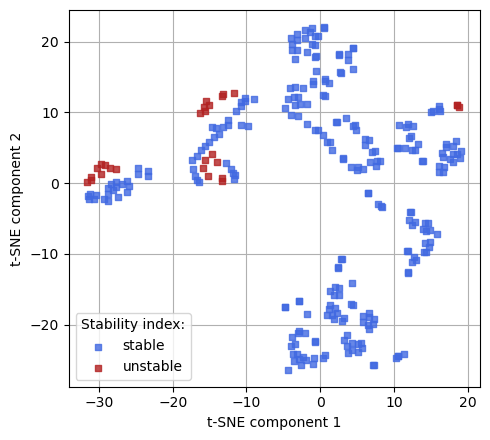

In [45]:
# Visualize the embedding (TSI index).
fig, ax = plt.subplots(figsize=(5, 4.5))
colors = ['royalblue', 'firebrick']
class_names, y_encoded = np.unique(data['TSI'].values, return_inverse=True)
for class_id, class_name in enumerate(class_names):
    mask = y_encoded == class_id
    if class_name == 0:
        class_name = 'stable'
    else:
        class_name = 'unstable'
    ax.scatter(data_2d[mask, 0], data_2d[mask, 1], marker='s', s=20, alpha=0.8,
               color=colors[class_id], label=class_name, zorder=3)
ax.set_xlabel("t-SNE component 1")
ax.set_ylabel("t-SNE component 2")
ax.legend(title='Stability index:', loc='lower left')
ax.grid(which='major', axis='both', zorder=0)
fig.tight_layout()
#plt.savefig('tsne-tsi.pdf')
plt.show()